# ACA Marketplace Claim Denials and Appeals
If high denial rates were mainly caused by review errors, insurers that deny
more claims should also have more of those denials reversed on appeal. In other
words, we'd expect a positive correlation between denial rate and overturn rate.

**Hypothesis test** (n = 131 insurers):

- $H_0: \rho = 0$ — no correlation between denial rate and overturn rate
- $H_1: \rho \neq 0$ — denial rate and overturn rate are correlated

I test this with a Pearson correlation, then with a multiple regression that
controls for appeal rate and insurer size.

## Loading the data

The workbook has three sheets — individual medical plans, individual
dental, and SHOP. I use "Transparency 2026 - Ind QHP" for individual
medical.

The first two rows are a title and a legend, so the real column
headers are on row 3. Hence `skiprows=2`.

In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

df = pd.read_excel(
    "Transparency_in_Coverage_PUF.xlsx",
    sheet_name="Transparency 2026 - Ind QHP",
    skiprows=2
)

print(df.shape)
df.head(10)

(4159, 44)


,Individual/SHOP,Exchange_Type,State,Issuer_Name,Issuer_ID,Is_Issuer_New_to_Exchange?(Yes_or_No),SADP_Only,Plan_ID,Plan_Type,QHP or SADP?,...,Plan_Number_Claims_Denied_Not_Medically_Necessary_Behavioral_Health_Only,Plan_Number_Claims_Denied_Due_To_Enrolle_Benefit_Limit_Reached,Plan_Number_Claims_Denied_Due_To_Member_Not_Covered,Plan_Number_Claims_Denied_Due_To_Investigational_Experimental_Cosmetic_Proceduce,Plan_Number_Claims_Denied_Due_To_Administrative_Reason,Plan_Number_Claims_Denied_Other,Rate_Review,Financial_Information,Average Monthly Enrollment,Average Monthly Disenrollment
0,Individual,SBE-FP,OR,PacificSource Health Plans,10091,No,No,10091OR0770001,EPO,QHP,...,NaN,NaN,NaN,NaN,NaN,NaN,https://ratereview.healthcare.gov/,https://www.naic.org/cis_refined_results.htm?T...,*,*
1,Individual,SBE-FP,OR,PacificSource Health Plans,10091,No,No,10091OR0770002,EPO,QHP,...,NaN,NaN,NaN,NaN,NaN,NaN,https://ratereview.healthcare.gov/,https://www.naic.org/cis_refined_results.htm?T...,*,*
2,Individual,SBE-FP,OR,PacificSource Health Plans,10091,No,No,10091OR0770003,EPO,QHP,...,NaN,NaN,NaN,NaN,NaN,NaN,https://ratereview.healthcare.gov/,https://www.naic.org/cis_refined_results.htm?T...,*,*
3,Individual,SBE-FP,OR,PacificSource Health Plans,10091,No,No,10091OR0770004,EPO,QHP,...,NaN,NaN,NaN,NaN,NaN,NaN,https://ratereview.healthcare.gov/,https://www.naic.org/cis_refined_results.htm?T...,*,*
4,Individual,SBE-FP,OR,PacificSource Health Plans,10091,No,No,10091OR0770005,EPO,QHP,...,NaN,NaN,NaN,NaN,NaN,NaN,https://ratereview.healthcare.gov/,https://www.naic.org/cis_refined_results.htm?T...,*,*
5,Individual,SBE-FP,OR,PacificSource Health Plans,10091,No,No,10091OR0770006,EPO,QHP,...,NaN,NaN,NaN,NaN,NaN,NaN,https://ratereview.healthcare.gov/,https://www.naic.org/cis_refined_results.htm?T...,*,*
6,Individual,SBE-FP,OR,PacificSource Health Plans,10091,No,No,10091OR0770007,EPO,QHP,...,NaN,NaN,NaN,NaN,NaN,NaN,https://ratereview.healthcare.gov/,https://www.naic.org/cis_refined_results.htm?T...,*,*
7,Individual,SBE-FP,OR,PacificSource Health Plans,10091,No,No,10091OR0780001,EPO,QHP,...,NaN,NaN,NaN,NaN,NaN,NaN,https://ratereview.healthcare.gov/,https://www.naic.org/cis_refined_results.htm?T...,*,*
8,Individual,SBE-FP,OR,PacificSource Health Plans,10091,No,No,10091OR0780002,EPO,QHP,...,NaN,NaN,NaN,NaN,NaN,NaN,https://ratereview.healthcare.gov/,https://www.naic.org/cis_refined_results.htm?T...,*,*
9,Individual,FFE,WY,Blue Cross Blue Shield of Wyoming,11269,No,No,11269WY0070004,PPO,QHP,...,39,995,2393,178,8256,855,https://ratereview.healthcare.gov/,https://www.naic.org/cis_refined_results.htm?T...,245,21


In [56]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4159 entries, 0 to 4158
Data columns (total 44 columns):
 #   Column                                                                            Non-Null Count  Dtype  
---  ------                                                                            --------------  -----  
 0   Individual/SHOP                                                                   4159 non-null   object 
 1   Exchange_Type                                                                     4159 non-null   object 
 2   State                                                                             4159 non-null   object 
 3   Issuer_Name                                                                       4159 non-null   object 
 4   Issuer_ID                                                                         4159 non-null   int64  
 5   Is_Issuer_New_to_Exchange?(Yes_or_No)                                             4159 non-null   object 
 6   

In [57]:
df["State"].value_counts()

State
TX    838
FL    410
WI    317
NC    235
AZ    201
OH    195
OK    191
NE    168
TN    163
MI    147
SC    134
MO    123
IA    122
LA    101
MT     90
IN     80
SD     67
KS     66
ND     59
OR     59
UT     57
AL     55
AR     52
MS     51
NH     46
DE     40
WV     37
WY     23
HI     17
AK     15
Name: count, dtype: int64

In [58]:
df["Issuer_Claims_Received_In_Network"].isna().sum()

np.int64(352)

## Three things stand out:

Most count columns came in as text rather than numbers, because
of the suppression markers in the legend. These need converting
before any arithmetic.

The non-null counts fall into groups: 4,159 for identifiers,
3,807 for the issuer-level columns, ~2,559 for most plan-level
columns. So 352 rows carry no issuer data at all. (4,159-3807=352)

Texas accounts for 838 rows — a fifth of the file. But rows are
plans, not insurers, so this may reflect the number of plans sold
rather than the number of insurers operating there.

## The four kinds of missing

The legend defines four markers, and they don't mean the same thing:

- `*` — not available
- `**` — suppressed, count too small
- `***` — not required for this plan type
- `N/A` — issuer or plan new to the exchange

This explains the `object` types. It also matters for interpretation: `**` isn't
random. CMS suppresses small counts, so the insurers that drop out are
systematically the small ones. Anything I conclude describes larger insurers.

## An inconsistency in the plan-level columns

Two plan-level columns show 2,656 non-null values while their neighbours show
2,559. No obvious reason those two would be more complete, so worth checking.

In [59]:
extra = df[
    df["Plan_Number_Claims_Denied_Referral_Required"].notna()
    & df["Plan_Number_Claims_Denied_In_Network"].isna()
]
print(len(extra))
extra[["State", "Issuer_Name", "Plan_Type", "Metal_Level"]].head(20)

97


,State,Issuer_Name,Plan_Type,Metal_Level
19,WY,Blue Cross Blue Shield of Wyoming,PPO,Silver
28,NC,Blue Cross and Blue Shield of NC,PPO,Bronze
689,OK,Medica Insurance Company,PPO,Gold
690,OK,Medica Insurance Company,PPO,Silver
698,OK,Medica Insurance Company,PPO,Bronze
699,OK,Medica Insurance Company,PPO,Gold
700,OK,Medica Insurance Company,PPO,Silver
701,OK,Medica Insurance Company,PPO,Gold
702,OK,Medica Insurance Company,PPO,Silver
703,OK,Medica Insurance Company,PPO,Bronze


In [60]:
extra["Plan_Type"].value_counts()
extra["Issuer_Name"].value_counts()

Issuer_Name
Avera Health Plans, Inc.                            22
Medica Insurance Company                            15
Blue Cross and Blue Shield of South Carolina         9
Blue Cross and Blue Shield of Nebraska               9
Highmark BCBSD Inc.                                  8
Highmark Blue Cross Blue Shield West Virginia        7
Celtic Insurance Company                             6
Oscar Insurance Company                              6
Blue Cross and Blue Shield of Montana                4
Blue Cross Blue Shield of Oklahoma                   4
QualChoice Life & Health Insurance Company, Inc.     3
Blue Cross Blue Shield of Wyoming                    1
Blue Cross and Blue Shield of NC                     1
Blue Cross Blue Shield of North Dakota               1
USAble Mutual Insurance Company                      1
Name: count, dtype: int64

In [61]:
extra[[
    "Plan_Number_Claims_Denied_Referral_Required",
    "Plan_Number_Claims_Denied_Out_of_Network",
    "Plan_Number_Claims_Denied_In_Network"
]].head(20)

,Plan_Number_Claims_Denied_Referral_Required,Plan_Number_Claims_Denied_Out_of_Network,Plan_Number_Claims_Denied_In_Network
19,***,***,NaN
28,***,***,NaN
689,***,***,NaN
690,***,***,NaN
698,***,***,NaN
699,***,***,NaN
700,***,***,NaN
701,***,***,NaN
702,***,***,NaN
703,***,***,NaN


Two plan-level columns showed 2,656 non-null values while their neighbors showed 2,559. The 97 extra rows contain *** — not required, per the legend — rather than actual counts. Some issuers typed the placeholder where others left the cell empty. The non-null count difference is an encoding artifact, not a difference in reporting completeness.

Pandas counts a typed *** as a non-null value and a truly empty cell as null, so the column looks more complete while carrying the same information: none. The difference is an encoding artifact, not a difference in reporting.

This doesn't affect my analysis, which uses issuer-level columns. But it's a reminder that non-null does not mean present — isna() only catches true blanks, and any placeholder someone typed survives as a "value."

# Data Cleaning 
## Collapsing to issuer level

My question is about insurers, so one insurer should be one row. Right now each row is a plan, and the Issuer columns repeat identical totals across every plan an issuer sells.

Leaving it at plan level would weight each insurer by how many plans it happens to sell, and the rows wouldn't be independent observations.

Verifying first that nothing actually varies within an issuer.

In [62]:
df.groupby("Issuer_ID")["Issuer_Claims_Denied_In_Network"].nunique().value_counts()

Issuer_Claims_Denied_In_Network
1    159
0     26
Name: count, dtype: int64

In [63]:
issuer_cols = [
    "State",
    "Issuer_ID",
    "Issuer_Name",
    "Issuer_Claims_Received_In_Network",
    "Issuer_Claims_Denied_In_Network",
    "Issuer_Internal_Appeals_Filed",
    "Issuer_Number_Internal_Appeals_Overturned",
    "Issuer_Percent_Internal_Appeals_Overturned",
]

issuers = df[issuer_cols].drop_duplicates()
print(issuers.shape)
issuers.head()

(185, 8)


,State,Issuer_ID,Issuer_Name,Issuer_Claims_Received_In_Network,Issuer_Claims_Denied_In_Network,Issuer_Internal_Appeals_Filed,Issuer_Number_Internal_Appeals_Overturned,Issuer_Percent_Internal_Appeals_Overturned
0,OR,10091,PacificSource Health Plans,3771.0,658,136,12,**
9,WY,11269,Blue Cross Blue Shield of Wyoming,1305051.0,229909,434,173,39.86
20,NC,11512,Blue Cross and Blue Shield of NC,16183703.0,3116071,2160,779,36.06
137,TX,11718,"Community Health Choice Texas, Inc.",NaN,NaN,NaN,NaN,NaN
143,NH,13219,"Boston Medical Center Health Plan, Inc.",NaN,NaN,NaN,NaN,NaN


## Converting the Measure Columns

These columns hold the missing markers as text, so they need converting before any
arithmetic. Counting each marker first — the suppressed values in particular aren't
random, and I want to know how many insurers I'm losing and why.

In [64]:
measures = [
    "Issuer_Claims_Received_In_Network",
    "Issuer_Claims_Denied_In_Network",
    "Issuer_Internal_Appeals_Filed",
    "Issuer_Number_Internal_Appeals_Overturned",
    "Issuer_Percent_Internal_Appeals_Overturned",
]

for col in measures:
    bad = issuers[col][pd.to_numeric(issuers[col], errors="coerce").isna()]
    print(col)
    print(bad.value_counts(dropna=False))
    print()

Issuer_Claims_Received_In_Network
Issuer_Claims_Received_In_Network
NaN    26
Name: count, dtype: int64

Issuer_Claims_Denied_In_Network
Issuer_Claims_Denied_In_Network
NaN    26
**      1
Name: count, dtype: int64

Issuer_Internal_Appeals_Filed
Issuer_Internal_Appeals_Filed
NaN    26
**     11
Name: count, dtype: int64

Issuer_Number_Internal_Appeals_Overturned
Issuer_Number_Internal_Appeals_Overturned
NaN    26
**     21
Name: count, dtype: int64

Issuer_Percent_Internal_Appeals_Overturned
Issuer_Percent_Internal_Appeals_Overturned
**     28
NaN    26
Name: count, dtype: int64



In [65]:
for col in measures:
    issuers[col] = pd.to_numeric(issuers[col], errors="coerce")

issuers.dtypes

State                                          object
Issuer_ID                                       int64
Issuer_Name                                    object
Issuer_Claims_Received_In_Network             float64
Issuer_Claims_Denied_In_Network               float64
Issuer_Internal_Appeals_Filed                 float64
Issuer_Number_Internal_Appeals_Overturned     float64
Issuer_Percent_Internal_Appeals_Overturned    float64
dtype: object

## Filtering and building the rates

CMS only requires full reporting above a claim volume threshold, so I'm keeping
issuers with more than 1,000 in-network claims. Below that the rates get unstable —
a handful of denials swings the percentage wildly.

Denial rate is denied over received. The overturn rate is already reported as a
column, so no calculation needed there.

In [66]:
analysis = issuers[issuers["Issuer_Claims_Received_In_Network"] > 1000].copy()

analysis["denial_rate"] = (
    analysis["Issuer_Claims_Denied_In_Network"]
    / analysis["Issuer_Claims_Received_In_Network"]
    * 100
)

print(len(analysis))

157


In [67]:
analysis = analysis.dropna(subset=[
    "denial_rate",
    "Issuer_Percent_Internal_Appeals_Overturned"
])

print(len(analysis))

131


In [68]:
print(analysis["denial_rate"].describe())
print()
print(analysis["Issuer_Percent_Internal_Appeals_Overturned"].describe())

count    131.000000
mean      18.329717
std        6.041156
min        2.695357
25%       15.346914
50%       18.965693
75%       21.990753
max       32.650633
Name: denial_rate, dtype: float64

count    131.000000
mean      39.982214
std       17.303334
min        0.000000
25%       30.665000
50%       38.090000
75%       50.075000
max       88.240000
Name: Issuer_Percent_Internal_Appeals_Overturned, dtype: float64


## Exploring the variables

Looking at distributions before modelling, particularly the outcome — the spread
in overturn rates is what the analysis is explaining

In [69]:
analysis["Issuer_Claims_Received_In_Network"].describe() # Claim volume spans 7,564 to 58.8M with a mean 3x the median — heavily
# right-skewed, so I take the log before modelling

count    1.310000e+02
mean     3.087654e+06
std      7.032204e+06
min      7.564000e+03
25%      4.025815e+05
50%      1.009831e+06
75%      2.764808e+06
max      5.880674e+07
Name: Issuer_Claims_Received_In_Network, dtype: float64

In [70]:
analysis["appeal_rate"] = (
    analysis["Issuer_Internal_Appeals_Filed"]
    / analysis["Issuer_Claims_Denied_In_Network"]
    * 100
)

analysis["log_claims"] = np.log(analysis["Issuer_Claims_Received_In_Network"])

### Histograms of denial and overturn rates

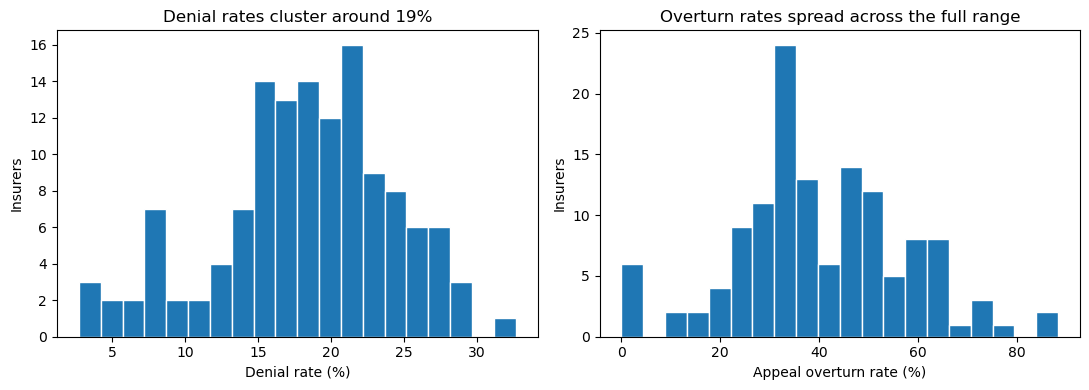

In [71]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(analysis["denial_rate"], bins=20, edgecolor="white")
axes[0].set_xlabel("Denial rate (%)")
axes[0].set_ylabel("Insurers")
axes[0].set_title("Denial rates cluster around 19%")

axes[1].hist(
    analysis["Issuer_Percent_Internal_Appeals_Overturned"],
    bins=20, edgecolor="white"
)
axes[1].set_xlabel("Appeal overturn rate (%)")
axes[1].set_ylabel("Insurers")
axes[1].set_title("Overturn rates spread across the full range")

plt.tight_layout()
plt.savefig("figures/distributions.png", dpi=150, bbox_inches="tight")
plt.show();

## Box Plots

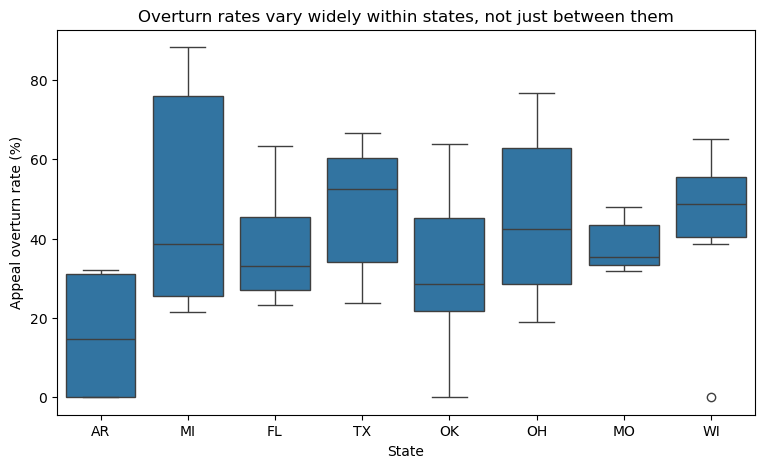

In [72]:
top_states = analysis["State"].value_counts().head(8).index
subset = analysis[analysis["State"].isin(top_states)]

plt.figure(figsize=(9, 5))
sns.boxplot(data=subset, x="State", y="Issuer_Percent_Internal_Appeals_Overturned")
plt.xlabel("State")
plt.ylabel("Appeal overturn rate (%)")
plt.title("Overturn rates vary widely within states, not just between them")
plt.savefig("figures/by_state.png", dpi=150, bbox_inches="tight")
plt.show();

Michigan's insurers span roughly 22% to 90%. That's a wider range than the gap between any two state medians.

State doesn't explain much. The boxes overlap heavily, so knowing an insurer's state tells you little about its overturn rate. That supports leaving state out of the model

In [73]:
subset["State"].value_counts()

State
TX    12
OH    10
FL     8
WI     8
AR     6
MI     6
OK     6
MO     6
Name: count, dtype: int64

These are small groups so individual state medians aren't
meaningful. 

## Heat Map

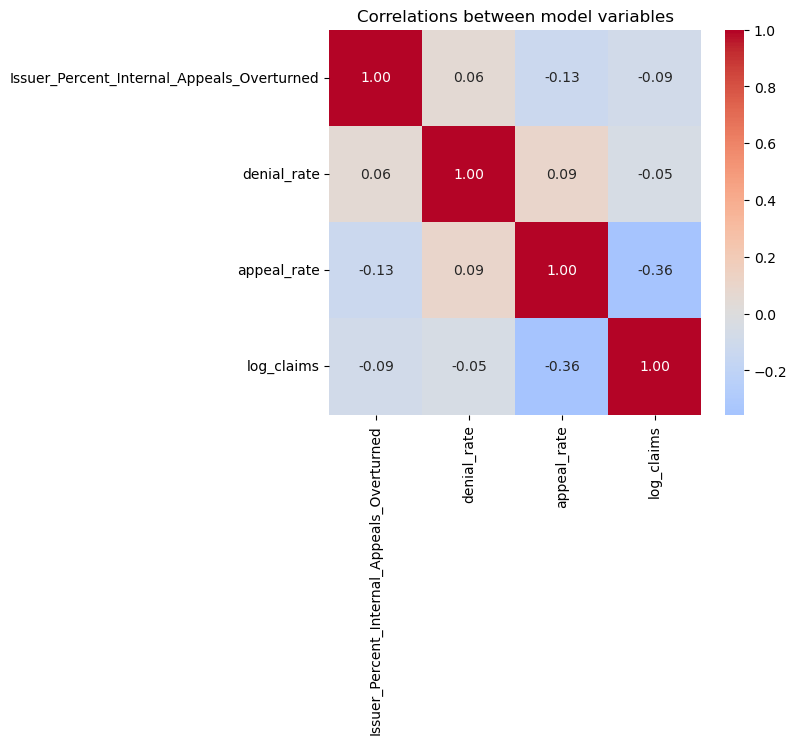

In [74]:
model_vars = analysis[[
    "Issuer_Percent_Internal_Appeals_Overturned",
    "denial_rate",
    "appeal_rate",
    "log_claims"
]]

plt.figure(figsize=(6, 5))
sns.heatmap(model_vars.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlations between model variables")

plt.savefig("figures/correlations.png", dpi=150, bbox_inches="tight")
plt.show();

* None of the three predictors correlates much with overturn rate (0.06, −0.13, −0.09). 
    
* Appeal rate and claim volume correlate at −0.36 — bigger insurers get a smaller share of denials appealed.
    
* Not strong enough to be a collinearity problem.

The median denial rate is close to the ~19% national figure KFF published from
this same file, which suggests the cleaning and filtering did not distort the data.

The appeal rate is strikingly low — a median of 0.25%, which can mean half these insurers
see far fewer appeals. That makes overturn rates noisy for
many of them, since the percentage is computed from a handful of cases.

## Scatterplot
* Do denial rate and overturn rate move together?

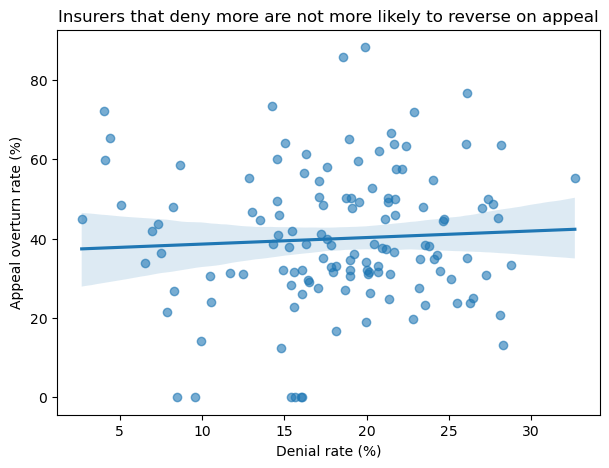

In [75]:
plt.figure(figsize=(7, 5))
ax = sns.regplot(
    data=analysis,
    x="denial_rate",
    y="Issuer_Percent_Internal_Appeals_Overturned",
    scatter_kws={"alpha": 0.6}
)
ax.set_xlabel("Denial rate (%)")
ax.set_ylabel("Appeal overturn rate (%)")
ax.set_title("Insurers that deny more are not more likely to reverse on appeal")
plt.savefig("figures/denial_vs_overturn.png", dpi=150, bbox_inches="tight")
plt.show();

### Correlation

In [76]:
analysis["denial_rate"].corr(
    analysis["Issuer_Percent_Internal_Appeals_Overturned"],
    method="pearson"
)

np.float64(0.05761145469536774)

In [77]:
#Spearman correlation as a robustness check
#it uses ranks, so it doesn't assume normality and isn't pulled by outliers
from scipy.stats import spearmanr, pearsonr

r, p_r = pearsonr(analysis["denial_rate"], analysis["Issuer_Percent_Internal_Appeals_Overturned"])
rho, p_rho = spearmanr(analysis["denial_rate"], analysis["Issuer_Percent_Internal_Appeals_Overturned"])

print(f"Pearson r = {r:.2f}, p = {p_r:.2f}")
print(f"Spearman rho = {rho:.2f}, p = {p_rho:.2f}")

Pearson r = 0.06, p = 0.51
Spearman rho = 0.06, p = 0.51


Spearman gives the same answer as Pearson (rho = 0.06, p = 0.51). Because Spearman uses ranks, this confirms the null result is not caused by outliers or by the overturn rate not being normally distributed.

## Multiple linear regression

Testing the same relationship with controls. Claim volume is logged because it's
heavily skewed — a few very large insurers would otherwise dominate the fit.
Appeal rate is included because the overturn rate is conditional on appeals
happening at all.

State is left out because the box plots showed it explains little of the variation in overturn rates.

### Model

In [78]:
model = smf.ols(
    "Issuer_Percent_Internal_Appeals_Overturned ~ denial_rate + appeal_rate + log_claims",
    data=analysis
).fit()

print(model.summary())

                                        OLS Regression Results                                        
Dep. Variable:     Issuer_Percent_Internal_Appeals_Overturned   R-squared:                       0.042
Model:                                                    OLS   Adj. R-squared:                  0.019
Method:                                         Least Squares   F-statistic:                     1.835
Date:                                        Fri, 16 Oct 2026   Prob (F-statistic):              0.144
Time:                                                13:57:30   Log-Likelihood:                -556.07
No. Observations:                                         131   AIC:                             1120.
Df Residuals:                                             127   BIC:                             1132.
Df Model:                                                   3                                         
Covariance Type:                                    nonrobust            

### Residual check

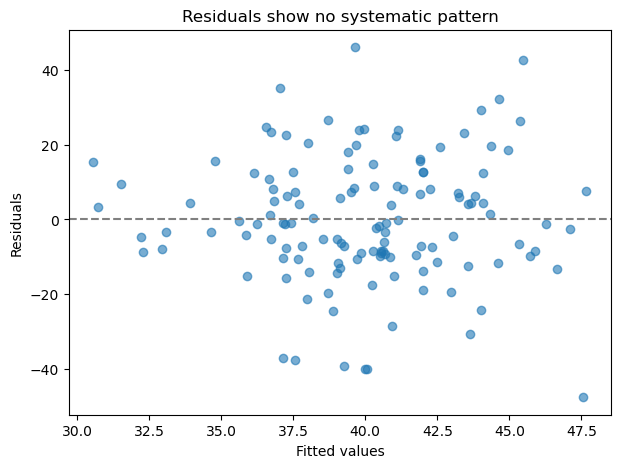

In [79]:
plt.figure(figsize=(7, 5))
plt.scatter(model.fittedvalues, model.resid, alpha=0.6)
plt.axhline(0, color="grey", linestyle="--")
plt.xlabel("Fitted values")
plt.ylabel("Residuals")
plt.title("Residuals show no systematic pattern")
plt.savefig("figures/residuals.png", dpi=150, bbox_inches="tight")
plt.show();

Residuals are scattered evenly around zero with no funnel or curve, so the OLS
assumptions hold reasonably well. The model isn't misspecified, it just doesn't
explain much.

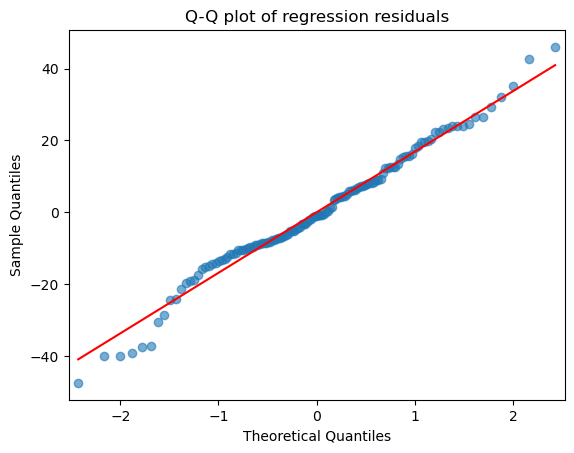

In [80]:
#Q-Q plot: checks whether the residuals are roughly normal
#if they are, the points fall close to the red line
import statsmodels.api as sm

sm.qqplot(model.resid, line="s", alpha=0.6)
plt.title("Q-Q plot of regression residuals")
plt.savefig("figures/qq_residuals.png", dpi=150, bbox_inches="tight")
plt.show();

Most residuals fall close to the line, so they are roughly normal. The lower tail drifts below the line: a few insurers have overturn rates much lower than the model predicts, which fits an outcome that cannot go below 0%. With 131 insurers, this small departure does not change the conclusions, but it is another reason a model built for percentages (binomial regression) would be a better next step.

## What I found

Across 131 insurers, denial rate and appeal overturn rate are essentially
uncorrelated (Pearson r = 0.06; Spearman rho = 0.06, p = 0.51). Insurers that deny more claims are no more likely to
reverse those denials when members appeal.

The regression says the same with controls in place. Denial rate is not
significant (p = 0.44), and the model explains about 4% of the variation in
overturn rates (R² = 0.042, F-test p = 0.14). Only appeal rate reaches
significance (−1.78, p = 0.04), though that sits inside a model that isn't
jointly significant, so it's suggestive at best.

**Takeaway:** a high denial rate does not by itself indicate an inaccurate review
process. Overturn rates range from 0% to nearly 90%, but no insurer-level
characteristic in this file accounts for that spread.

## Limitations

- 131 insurers, HealthCare.gov states only, in-network claims only.
- Insurer-level associations only, no causal claims.
- Small insurers are suppressed by CMS, so the findings describe larger insurers.
- Appeals are rare, so overturn rates for smaller insurers are noisy.
- The outcome is a percentage, and OLS doesn't know it is bounded at 0% and 100%. The Q-Q plot shows a small departure in the lower tail.
- Claims data is self-reported by insurers to CMS.

## Next steps

- **Binomial regression weighted by number of appeals**, which is built for "overturned out of appealed" outcomes and gives insurers with more appeals more weight.
- **Sensitivity check** on the claim-volume cutoff (for example, 500 and 5,000 claims instead of 1,000).
- **Add state-based marketplaces and employer plans** if comparable data becomes available.